# Case Study 1: First steps with PyTorch

_Kedrov, Viacheslav, 2320049._

This tutorial aims at
- **introducing you to basics of PyTorch**
- making you get familiar with Jupyter Notebooks
- making you get familiar with the submission of your homeworks on Digicampus

Complete the cells from this notebook and answer the questions in the Markdown cells.

**Once you have finished the tutorial**:
- run the whole Jupyter Notebook once
- then, export a copy of this notebook into a PDF file.

## Note for Homeworks Submission
**_After running_** your notebook with the results, export it into a PDF file.

**SUBMIT THE EXPORTED PDF FILE OF YOUR NOTEBOOK VIA DIGICAMPUS**

When uploading the notebook of your homework, please rename the notebook in the following format.

_Ntutorial_mustermann.pdf_
where N is the number of the tutorial (here 01) and mustermann is your family name.

# Getting the data

A toolbox (dataset.py) enables you to load the dataset from this tutorial.

The first time you run load_mitbih, the toolbox downloads the MIT BIH Arrhythmia Database from [Physionet](https://physionet.org/content/mitdb/1.0.0/) (around 100 MB, you need an internet connection). The database is on the WFDB format.

**If this takes too long**, download the already prepared file [dataset.npz](https://megastore.rz.uni-augsburg.de/get/zOxbKqGlsS/) and place it in the data/ subfolder (next to this notebook; create the folder if needed). As long as data/dataset.npz exists, load_mitbih downloads nothing.

Then, all heartbeats and their labels are extracted from the recordings: for each beat, 60 samples before the R peak and 300 samples after it are kept (the ECG is sampled at 360 Hz). The heartbeats are saved into the file data/dataset.npz, so that the next time you run load_mitbih, the dataset is directly loaded from this file.

load_mitbih returns 6 numpy arrays :
- Xtrain_full, Xtest : the heartbeats
- ytrain_full, ytest : the labels of the heartbeats
- rtrain_full, rtest : the name of the recording each heartbeat comes from. One recording corresponds to one patient.

The train set and the test set contain recordings from different patients (split proposed by de Chazal et al.).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

np.random.seed(42)
torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch {torch.__version__}, running on {device}')

PyTorch 2.14.1+cpu, running on cpu


In [3]:
from dataset import load_mitbih, FS

data_dir = 'data'  # folder where the dataset is downloaded and cached
Xtrain_full, ytrain_full, rtrain_full, Xtest, ytest, rtest = load_mitbih(data_dir)

**Question 1** (2 points)
- How many entries does the training set contain ?
- Display the first sample of the training set. Put the time in seconds on the x axis and the label of the sample as title.

(50994, 360)


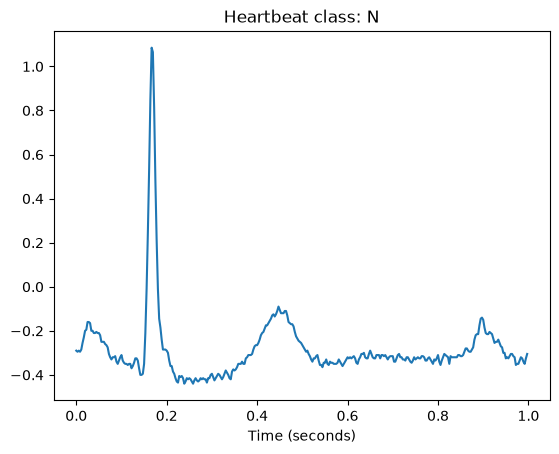

In [19]:
print(Xtrain_full.shape)

first_sample = Xtrain_full[0]
label = ytrain_full[0]
time = np.arange(len(first_sample)) / FS

plt.plot(time, first_sample)
plt.title(f'Heartbeat class: {label}')
plt.xlabel('Time (seconds)')

plt.show()

**Answer**

Set contains **50994** entries 

**Question 2** (2 points)
- How many classes are contained in the training set ?
- Which class is the most represented ?

In [ ]:
# Your code

**Answer**

Your answer

The labels correspond to the following beats:
- N: Normal beat
- S: Supraventricular ectopic beat
- V: Ventricular ectopic beat
- Q: Paced or unclassifiable beat

# The ML Task of this tutorial

We aim at implementing a heartbeat classifier that will detect if a beat is Normal (N), or abnormal (S, V or Q).

## Relabelling of the classes
Therefore, you will have to apply a remapping of the labels ytrain_full and ytest, so that :
- y=0. if the heartbeat is normal
- y=1. if the heartbeat is abnormal

**Question 3** (2 points)
- Program a function my_label_fn in the cell below to perform the aforementioned remapping of the classes. The function should return a float32 numpy array.
- Apply this function to both your train and test set labels

In [ ]:
def my_label_fn(y):
    pass  # Your code

ytrain_bin = my_label_fn(ytrain_full)

In [ ]:
# apply the same relabeling function to the test set labels ytest
# store the result in ytest_bin
# Your code
pd.Series(ytest_bin).value_counts()

## Data Preparation

Caution : Do not touch the test set (Xtest, ytest) before final assessment of your model.

A first approach to train and assess the model during the development phase relies on the use of a training set, and a validation set.

For this tutorial, we will arbitrarily consider that 80% of the training set will serve for training the model and 20% will serve for validating it.

In [ ]:
# arbitrary split
split_idx = int(0.8 * len(Xtrain_full))
Xtrain, Xval = Xtrain_full[:split_idx], Xtrain_full[split_idx:]
ytrain, yval = ytrain_bin[:split_idx], ytrain_bin[split_idx:]

print('========TRAIN SET==============')
print(pd.Series(ytrain).value_counts(normalize=True))
print('========VALIDATION SET==============')
print(pd.Series(yval).value_counts(normalize=True))

**Question 4** (2 points)
- What do you notice in the class distribution between train and validation set ?
- Is it problematic ? Why ?

**Answer**

Your answer

- Some other options are proposed on [Scikit-Learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) to split data into training and evaluation (validation,test) sets.
- It is also possible to generate sets of indices, to build train/validation sets in order to perform [cross validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html).

**Question 5** (2 points)
- Complete the cell below to view the class distribution of train and validation set.
- What do you notice this time ?

In [ ]:
from sklearn.model_selection import train_test_split

Xtrain, Xval, ytrain, yval = train_test_split(
    Xtrain_full, ytrain_bin, test_size=0.20, stratify=ytrain_bin, random_state=42)

# Your code

**Answer**

Your answer

# From numpy arrays to PyTorch tensors

PyTorch works with tensors (torch.Tensor). Tensors are similar to numpy arrays, but they can be stored on a GPU and PyTorch can compute gradients with them. torch.from_numpy converts a numpy array into a tensor.

Neural networks are trained on batches of samples. PyTorch provides 2 classes for this :
- [Dataset](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) : a collection of samples. dataset[i] returns the sample i and its label (x_i, y_i). TensorDataset creates a Dataset from tensors.
- [DataLoader](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) : iterates over a Dataset batch by batch. It can also shuffle the samples at each epoch.

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

def make_loader(X, y, batch_size=32, shuffle=False):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

**Question 6** (3 points)
- Use make_loader to create train_loader (batch size 32, shuffled) and val_loader (batch size 256, not shuffled). The labels should have the shape (n, 1).
- Get one batch from train_loader and print the shape and dtype of the inputs and of the labels.
- Why do we shuffle the train set and not the validation set ?

In [ ]:
# Your code

**Answer**

Your answer

# Building a model with PyTorch

In PyTorch, a model is a nn.Module. In general 3 options can be used to build a model :
1. Use the nn.Sequential class to stack layers
2. Subclass nn.Module : the layers are created in \_\_init\_\_ and the computation is done in forward
3. Combine several nn.Module into a bigger one

Our models do not have a sigmoid on the last layer, they return a real value (logit). The sigmoid is done by the loss function nn.BCEWithLogitsLoss, which is numerically more stable.

In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Fifty ways of building a model

**Question 7** (5 points)
- Run the cell below.
- How many layers does the network contain ?
- Which computation does the first hidden layer perform ?
- Which activation function does the first hidden layer have ?
- Can you recover why the first hidden layer has 46208 parameters ?

In [ ]:
model = nn.Sequential(
    nn.Linear(360, 128),  # first hidden layer
    nn.ReLU(),
    nn.Linear(128, 128),  # second hidden layer
    nn.ReLU(),
    nn.Linear(128, 1),    # output layer (logit)
)
print(model)
for name, p in model.named_parameters():
    print(f'{name:10s} {tuple(p.shape)}')
print('Trainable parameters:', count_parameters(model))

**Answer**

Your answer

When subclassing nn.Module, you create the layers in \_\_init\_\_ and you perform the computation in forward.
This can be practical if you want to implement small operations like skipping a connection.

In [ ]:
class MySkipConnection(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_layer = nn.Linear(360, 128)
        self.hidden_layer = nn.Linear(128, 128)
        self.output_layer = nn.Linear(128, 1)

    def forward(self, x):
        h1 = torch.relu(self.input_layer(x))
        h2 = torch.relu(self.hidden_layer(h1))
        h2 = h2 + h1  # skip connection
        return self.output_layer(h2)

model = MySkipConnection()

**Question 8** (3 points)
- Print the model instantiated with MySkipConnection() and its number of trainable parameters
- Can you see the skip connection when printing the model ? Why ?
- Why does this model have the same number of parameters as the nn.Sequential model ?

In [ ]:
# Your code

**Answer**

Your answer

In [ ]:
# by combining modules, it is possible to decompose a model into smaller computation blocks
class Encoder(nn.Module):
    def __init__(self, in_features=360, hidden=128, dropout=0.2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(in_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),  # dropout rate = 0.2
        )

    def forward(self, x):
        return self.layers(x)

class Classifier(nn.Module):
    def __init__(self, hidden=128, n_outputs=1):
        super().__init__()
        self.layers = nn.Linear(hidden, n_outputs)

    def forward(self, x):
        return self.layers(x)

class MyModel2(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = Encoder()
        self.classifier = Classifier()

    def forward(self, x):
        return self.classifier(self.encoder(x))

model = MyModel2().to(device)  # move the parameters to the GPU if there is one
print(model)

### Training the model

With Keras, you would call compile and fit. With PyTorch, you write the training loop yourself. First, you have to specify :
- the [criterion](https://pytorch.org/docs/stable/nn.html#loss-functions) the network will have to optimize
- the [optimization algorithm](https://pytorch.org/docs/stable/optim.html) that is going to be used for training

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

One epoch is one pass over the whole train set, batch by batch :

In [ ]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()  # training mode: dropout is active
    total_loss, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        n += len(xb)
    return total_loss / n

**Question 9** (3 points)

Describe what the following lines of train_one_epoch do :
- optimizer.zero_grad()
- logits = model(xb)
- loss = loss_fn(logits, yb)
- loss.backward()
- optimizer.step()

**Answer**

Your answer

To monitor the training, we compute the loss and the accuracy on a dataset. For the accuracy, the logits have to be converted into classes :

In [ ]:
def binary_to_class(logits):
    # logit > 0  <=>  sigmoid(logit) > 0.5
    return (logits > 0).float()

**Question 10** (3 points)
- Complete the function evaluate below. It returns the mean loss and the accuracy of the model over all the samples of the loader.
- Why do we call model.eval() ? Why is the function decorated with @torch.no_grad() ?

In [ ]:
@torch.no_grad()
def evaluate(model, loader, loss_fn, to_class):
    """Return (mean loss, accuracy) of model on the samples of loader."""
    pass  # Your code

**Answer**

Your answer

The function fit below runs train_one_epoch for several epochs and stores the metrics in the dictionary history.

**Question 11** (2 points)

Complete fit so that it saves the parameters of the model (model.state_dict()) with [torch.save](https://pytorch.org/docs/stable/generated/torch.save.html) each time the validation accuracy improves (when ckpt_path is given). It does the same as the Keras callback ModelCheckpoint with save_best_only=True.

In [ ]:
def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs, to_class, ckpt_path=None):
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_val_acc = -1.0
    for epoch in range(1, epochs + 1):
        train_one_epoch(model, train_loader, loss_fn, optimizer)
        loss, acc = evaluate(model, train_loader, loss_fn, to_class)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, to_class)
        for key, value in zip(history, (loss, acc, val_loss, val_acc)):
            history[key].append(value)
        print(f'Epoch {epoch}/{epochs} - loss: {loss:.4f} - accuracy: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
        pass  # Your code
    return history

In [ ]:
ckpt_path = 'best_model.pt'
history = fit(model, train_loader, val_loader, loss_fn, optimizer,
              epochs=10, to_class=binary_to_class, ckpt_path=ckpt_path)

PyTorch only saves the parameters of the model (state_dict), not the architecture. To load the best model, you first instantiate the same architecture and then load the parameters :

In [ ]:
model = MyModel2().to(device)
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()

In [ ]:
pd.DataFrame(history)

**Question 12** (2 points)

- Make a plot with the training loss and validation loss among the epochs.
- Make a plot with the training accuracy and validation accuracy among the epochs.

In [ ]:
# Your code

**Question 13** (1 point)
- What would be the training accuracy of a classifier that always returns 0 on the train set ?

In [ ]:
# Your code

**Answer**

Your answer

### Evaluating the model
The fitted model can then make predictions on new data.

In [ ]:
#prediction on a few data: 5 normal and 5 abnormal beats from the validation set
idx = np.concatenate([np.where(yval == 0)[0][:5], np.where(yval == 1)[0][:5]])
Xnew, ynew = Xval[idx], yval[idx]
with torch.no_grad():
    outputs = model(torch.from_numpy(Xnew).to(device)).cpu().numpy()
print(outputs.ravel())
print(ynew)

**Question 14** (3 points)
- What do you notice on the outputs of the model compared to the labels ?
- How would you fix it ?
- Implement your solution in the functions below

In [ ]:
def predict_proba(model, X):
    """Return the probability of class 1 for each row of the NumPy array X."""
    pass  # Your code

def assign_class(proba, threshold=0.5):
    pass  # Your code

**Answer**

Your answer

Once the outputs have been converted into classes, you have the possibility to use Scikit-Learn evaluation tools to assess your models.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

yval_pred = assign_class(predict_proba(model, Xval))
print(classification_report(yval, yval_pred))
print(confusion_matrix(yval, yval_pred))

**Question 15** (3 points)
Considering that the positive class is the class 1.0, what is:
- the sensitivity of the classifier
- the positive predictive value of the classifier
- the specificity of the classifier

on the validation set ? (code is optional)

In [ ]:
# Your code

**Answer**

Your answer

**Question 16** (4 points)
- Assess your model on the test set (Xtest, ytest_bin)
- Report : Sensitivity, positive predictive value, f1-score of your classifier

In [ ]:
# Your code

**Answer**

Your answer

## Advanced

The previous ML task consisted in a binary classification (Normal beats, vs Abnormal beats).
We will now try to perform the multiclass classification (N,S,V beats).

**Question 17** (5 points)
- From Xtrain_full, ytrain_full, rtrain_full, remove the samples that belong to the Q class. Store them in Xmc, ymc, rmc. Do the same on the test set (Xtest_mc, ytest_mc).
- Explain why we remove the samples from the Q class
- Perform again the split between train and validation set (stratified, 20% for validation)
- Display the class distribution between your train and validation set

In [ ]:
# Your code

**Answer**

Your answer

**Question 18** (2 points)
- [nn.CrossEntropyLoss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) needs the labels as class indices 0,...,C-1 (int64). Complete the cell below to encode the labels of the train, validation and test sets.
- What does it mean regarding the shape of the last layer of the neural network ?

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
# Your code
print(label_encoder.classes_)

**Answer**

Your answer

**Question 19** (1 point)
Considering that the classes are exclusive, which function converts the C logits into probabilities ? Why don't we put it at the end of the model with nn.CrossEntropyLoss ?

**Answer**

Your answer

**Question 20** (1 point)
Considering that the classes are exclusive, what should be the loss function ?

**Answer**

Your answer

**Question 21** (2 points)
Adapt the network architecture you used before to perform the multiclass classification. Store it in model_mc.

In [ ]:
# Your code

For the multiclass case, the predicted class is the class with the highest logit :

In [ ]:
def multiclass_to_class(logits):
    return logits.argmax(dim=1)

def predict_multiclass(model, X):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(X).to(device))
    return multiclass_to_class(logits).cpu().numpy()

**Question 22** (2 points)
- Create the data loaders, the loss and an Adam optimizer (learning rate 1e-3). Train your network on the train set with fit and keep the best model.
- Plot the train and validation loss.

In [ ]:
# Your code

**Question 23** (4 points)
- Assess your model on the validation set.
- Display the classification report.
- If necessary, update your architecture, loss, hyperparameters to improve the performance of your classifier on the validation set. The classes are imbalanced : you can have a look at the weight argument of nn.CrossEntropyLoss, or at [WeightedRandomSampler](https://pytorch.org/docs/stable/data.html#torch.utils.data.WeightedRandomSampler) for the DataLoader.
- Describe what you updated in the classifier you proposed.

In [ ]:
# Your code

**Answer**

Your answer

**Question 24** (3 points)
- Assess your model on the test set.
- Compare your results to the results obtained on the validation set : if there are differences in terms of performance, describe them
- What does this suggest regarding your model ?

In [ ]:
# Your code

**Answer**

Your answer

**Question 25** (4 points)

The validation set should be built like the test set : with patients that are not in the train set.
- Use [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html) with the record names rmc as groups to build a train/validation split (first fold of 5). Check that no recording is in both sets.
- Train the same architecture as in Question 21 on this split.
- Plot the train and validation loss of this training. What do you observe ?
- Compare the classification reports on the validation and test sets. What do you notice compared to Question 24 ?

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

# Your code

**Answer**

Your answer